# **🔗Imports**

In [54]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader, Dataset, random_split
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.manifold import TSNE
from PIL import Image
from torchvision import transforms, datasets
import pandas as pd



# **📁 Kaggle Dataset Path Setup**


In [55]:
# Flowers102 is available directly from torchvision.
# No additional dataset package is needed.
# We resize images to 32x32 to keep the same VAE architecture used for CIFAR experiments.


In [56]:
import os

DATA_ROOT = "/kaggle/working/flower102_data"
OUTPUT_DIR = "/kaggle/working"

os.makedirs(DATA_ROOT, exist_ok=True)

print("Dataset directory:", DATA_ROOT)
print("Output directory:", OUTPUT_DIR)


Dataset directory: /kaggle/working/flower102_data
Output directory: /kaggle/working


In [57]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Flowers102 images have variable sizes, so we resize them to 32x32.
data_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

full_train_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="train",
    transform=data_transform,
    download=True
)

val_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="val",
    transform=data_transform,
    download=True
)

test_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="test",
    transform=data_transform,
    download=True
)

train_dataset = full_train_dataset

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


100%|██████████| 345M/345M [00:11<00:00, 29.7MB/s] 
100%|██████████| 502/502 [00:00<00:00, 2.63MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 24.5MB/s]

Train: 1020
Validation: 1020
Test: 6149


# **⚙️Hyperparameters + Device**

In [58]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = torch.cuda.is_available()
NUM_WORKERS = 2

BATCH_SIZE = 64
LATENT_DIM = 32
RIESZ_S = 2.0
LR = 1e-3
EPOCHS = 50
HIDDEN_DIM = 400

# Flowers102 image parameters
# Images are resized to 32x32 to keep the same architecture.
IN_CHANNELS = 3
IMAGE_SIZE = (32, 32)
INPUT_DIM = IN_CHANNELS * IMAGE_SIZE[0] * IMAGE_SIZE[1]

# Flowers102 has 102 flower categories
NUM_CLASSES = 102


# **📄Dataset**

In [59]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import numpy as np

transform_flowers102 = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

full_train_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="train",
    transform=transform_flowers102,
    download=True
)

val_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="val",
    transform=transform_flowers102,
    download=True
)

test_dataset = datasets.Flowers102(
    root=DATA_ROOT,
    split="test",
    transform=transform_flowers102,
    download=True
)

train_dataset = full_train_dataset

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=100,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=100,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

NUM_CLASSES = 102

# torchvision Flowers102 may not expose class names in all versions.
# Use safe placeholder names for visualization and tables.
if hasattr(full_train_dataset, "classes"):
    CLASS_NAMES = full_train_dataset.classes
else:
    CLASS_NAMES = [f"class_{i}" for i in range(NUM_CLASSES)]

print("DEVICE:", DEVICE)
print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))
print("NUM_CLASSES:", NUM_CLASSES)
print("Sample image shape:", train_dataset[0][0].shape)   # [3, 32, 32]
print("Sample label:", train_dataset[0][1])
print("First 20 classes:", CLASS_NAMES[:20])


DEVICE: cuda
Train: 1020
Val: 1020
Test: 6149
NUM_CLASSES: 102
Sample image shape: torch.Size([3, 32, 32])
Sample label: 0
First 20 classes: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily']


===== Flowers102 dataset information =====
Train size: 1020
Validation size: 1020
Test size: 6149
Number of classes: 102
First 20 class names: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily']
Sample image shape: torch.Size([3, 32, 32])



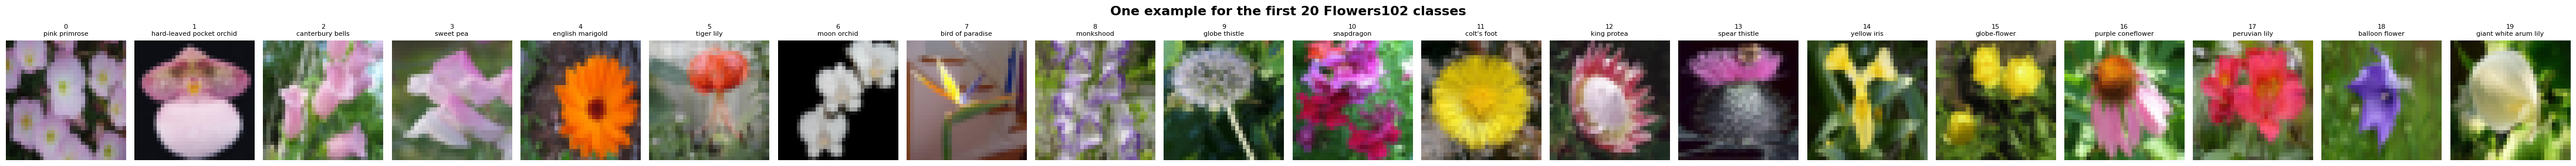

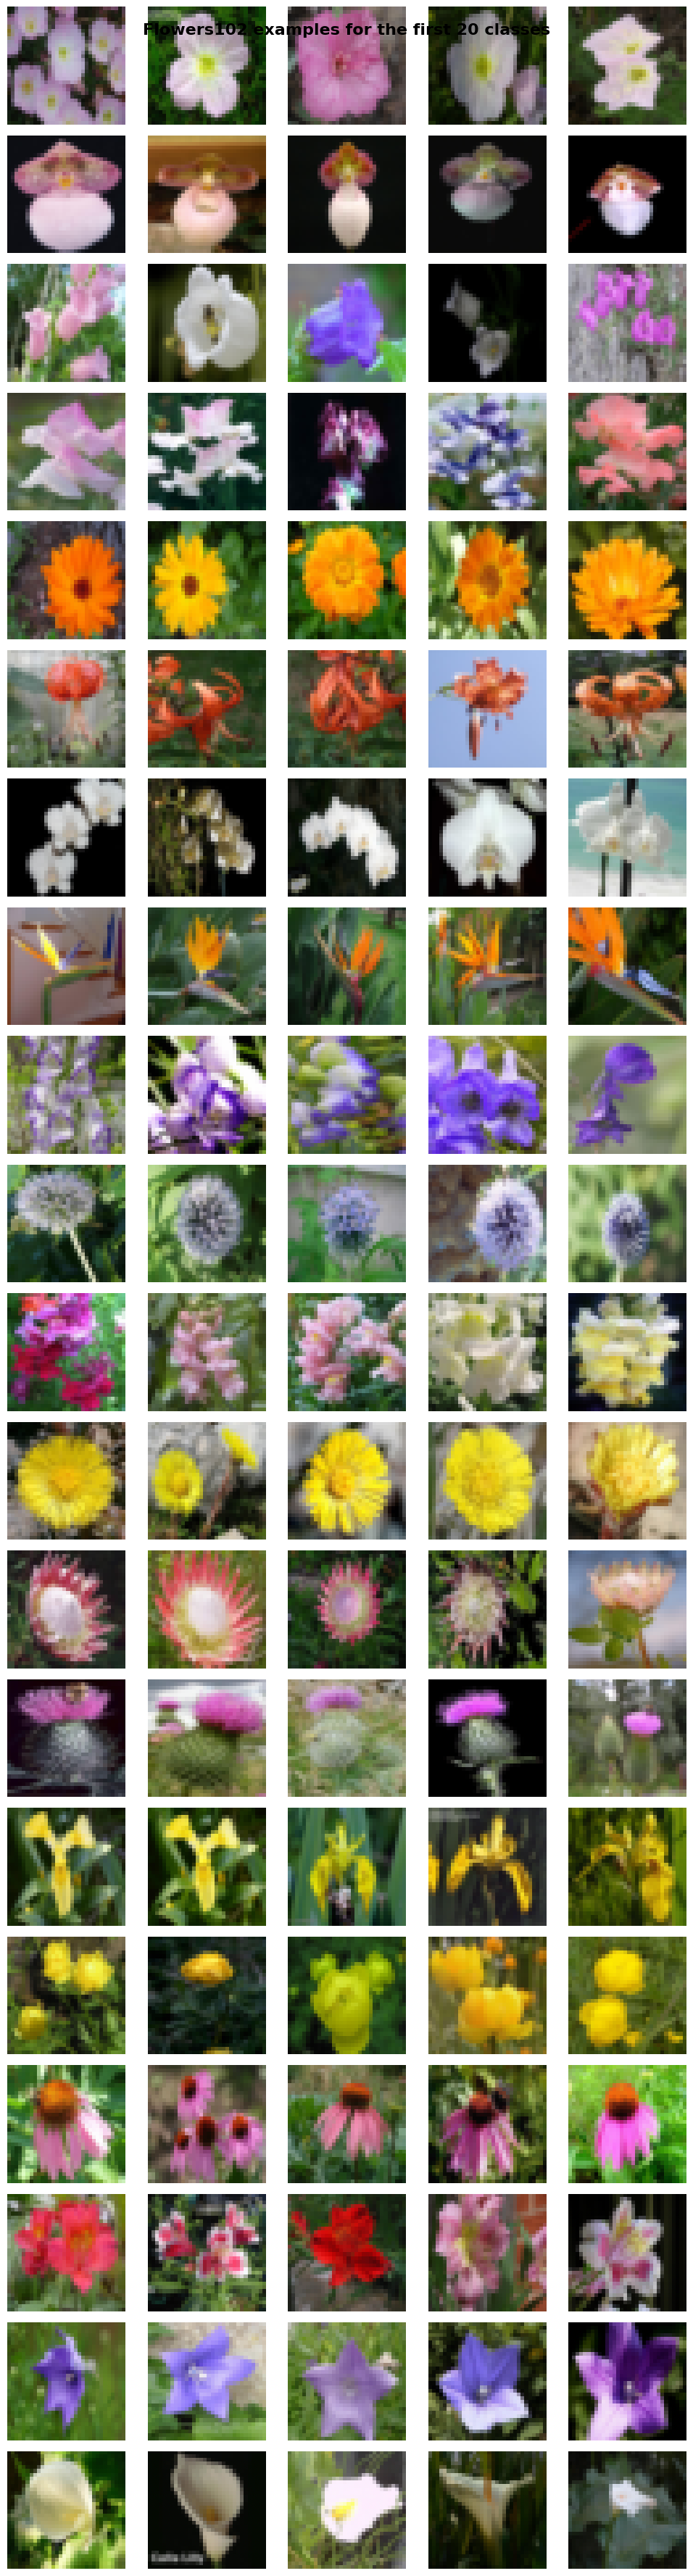

In [60]:
# =========================
# Flowers102 dataset information and visualization
# =========================

import numpy as np
import matplotlib.pyplot as plt

print("===== Flowers102 dataset information =====")
print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_dataset))
print("Number of classes:", NUM_CLASSES)
print("First 20 class names:", CLASS_NAMES[:20])
print("Sample image shape:", train_dataset[0][0].shape)
print()


def tensor_to_image(img_tensor):
    """
    Convert a tensor image [C, H, W] in [0, 1] to numpy image [H, W, C].
    """
    img = img_tensor.detach().cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0.0, 1.0)
    return img


def collect_one_example_per_class(dataset, num_classes, max_classes=20):
    """
    Flowers102 does not use .data and .targets like CIFAR.
    Therefore we scan the dataset and collect one image per class.
    """
    n_classes_to_show = min(max_classes, num_classes)
    examples = {}

    for img, label in dataset:
        label = int(label)
        if label < n_classes_to_show and label not in examples:
            examples[label] = img

        if len(examples) == n_classes_to_show:
            break

    return examples


def collect_grid_examples_per_class(dataset, num_classes, n_per_class=5, max_classes=20):
    """
    Collect several examples for each class.
    """
    n_classes_to_show = min(max_classes, num_classes)
    examples = {i: [] for i in range(n_classes_to_show)}

    for img, label in dataset:
        label = int(label)
        if label < n_classes_to_show and len(examples[label]) < n_per_class:
            examples[label].append(img)

        if all(len(v) >= n_per_class for v in examples.values()):
            break

    return examples


def mostra_un_esempio_per_classe(dataset, class_names, max_classes=20):
    """
    Show one representative image for a subset of Flowers102 classes.
    Flowers102 has 102 classes, so visualizing all classes at once is too large.
    """
    n_classes_to_show = min(max_classes, len(class_names))
    examples = collect_one_example_per_class(dataset, len(class_names), max_classes=n_classes_to_show)

    fig, axes = plt.subplots(
        1,
        n_classes_to_show,
        figsize=(2.2 * n_classes_to_show, 3.0)
    )

    if n_classes_to_show == 1:
        axes = [axes]

    for class_idx in range(n_classes_to_show):
        axes[class_idx].axis("off")

        if class_idx in examples:
            axes[class_idx].imshow(tensor_to_image(examples[class_idx]))

        axes[class_idx].set_title(
            f"{class_idx}\n{class_names[class_idx]}",
            fontsize=8
        )

    plt.suptitle(
        f"One example for the first {n_classes_to_show} Flowers102 classes",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


def mostra_griglia_per_classe(dataset, class_names, n_per_class=5, max_classes=20):
    """
    Show a grid of images for a subset of Flowers102 classes.
    Each row corresponds to one class.
    """
    n_classes_to_show = min(max_classes, len(class_names))
    examples = collect_grid_examples_per_class(
        dataset,
        len(class_names),
        n_per_class=n_per_class,
        max_classes=n_classes_to_show
    )

    fig, axes = plt.subplots(
        n_classes_to_show,
        n_per_class,
        figsize=(2 * n_per_class, 1.8 * n_classes_to_show)
    )

    if n_classes_to_show == 1:
        axes = np.expand_dims(axes, axis=0)

    if n_per_class == 1:
        axes = np.expand_dims(axes, axis=1)

    for class_idx in range(n_classes_to_show):
        for j in range(n_per_class):
            axes[class_idx, j].axis("off")

            if j < len(examples[class_idx]):
                axes[class_idx, j].imshow(tensor_to_image(examples[class_idx][j]))

            if j == 0:
                axes[class_idx, j].set_ylabel(
                    class_names[class_idx],
                    fontsize=9,
                    rotation=0,
                    labelpad=35,
                    va="center"
                )

    plt.suptitle(
        f"Flowers102 examples for the first {n_classes_to_show} classes",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


# To avoid an excessively large figure, show only the first 20 classes.
mostra_un_esempio_per_classe(train_dataset, CLASS_NAMES, max_classes=20)
mostra_griglia_per_classe(train_dataset, CLASS_NAMES, n_per_class=5, max_classes=20)


# **📍</> Standard VAE**

In [61]:
# --- 1. Definizione Modello Standard VAE ---
class StandardVAE(nn.Module):
    def __init__(self):
        super(StandardVAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)

        # Invece di Mu e Scale, qui abbiamo Mu e Log-Varianza (standard VAE)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            # Calcoliamo la deviazione standard: std = exp(0.5 * log_var)
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        # Ritorniamo anche mu e logvar per calcolare la Loss KL
        return recon, z, mu, logvar

# --- 2. Loss Function (ELBO) ---
def loss_function(recon_x, x, mu, logvar):
    # A. Reconstruction Loss (MSE)
    # reduction='sum' è importante per bilanciare la KL Divergence
    MSE = F.mse_loss(recon_x, x, reduction='sum')

    # B. KL Divergence
    # Misura quanto la distribuzione appresa (mu, logvar) differisce da una Normale(0, 1)
    # Formula analitica per due gaussiane
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return MSE + KLD

# --- 3. Training Loop ---
def train_standard_vae():
    print(f"Start Training Standard VAE on {DEVICE}...")

    # Caricamento Dati

    model = StandardVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0

        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(DEVICE).view(-1, INPUT_DIM)

            optimizer.zero_grad()

            # Forward
            recon, z, mu, logvar = model(data)

            # Loss
            loss = loss_function(recon, data, mu, logvar)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Log
        avg_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss (ELBO): {avg_loss:.4f}")

    print("Training completato.")
    return model

# --- Esecuzione ---

model_v = train_standard_vae()


Start Training Standard VAE on cuda...
Epoch 1/50 | Loss (ELBO): 188.8725
Epoch 2/50 | Loss (ELBO): 156.2891
Epoch 3/50 | Loss (ELBO): 144.3663
Epoch 4/50 | Loss (ELBO): 141.5862
Epoch 5/50 | Loss (ELBO): 138.1188
Epoch 6/50 | Loss (ELBO): 133.7526
Epoch 7/50 | Loss (ELBO): 129.4923
Epoch 8/50 | Loss (ELBO): 127.1062
Epoch 9/50 | Loss (ELBO): 126.3831
Epoch 10/50 | Loss (ELBO): 125.8439
Epoch 11/50 | Loss (ELBO): 124.2421
Epoch 12/50 | Loss (ELBO): 120.8553
Epoch 13/50 | Loss (ELBO): 120.3834
Epoch 14/50 | Loss (ELBO): 118.8518
Epoch 15/50 | Loss (ELBO): 116.0646
Epoch 16/50 | Loss (ELBO): 114.8103
Epoch 17/50 | Loss (ELBO): 113.2339
Epoch 18/50 | Loss (ELBO): 112.8614
Epoch 19/50 | Loss (ELBO): 112.0392
Epoch 20/50 | Loss (ELBO): 110.7222
Epoch 21/50 | Loss (ELBO): 110.0382
Epoch 22/50 | Loss (ELBO): 108.8042
Epoch 23/50 | Loss (ELBO): 106.6400
Epoch 24/50 | Loss (ELBO): 105.8639
Epoch 25/50 | Loss (ELBO): 104.5173
Epoch 26/50 | Loss (ELBO): 104.3921
Epoch 27/50 | Loss (ELBO): 103.130

# **📍</> Geodesic Spherical VAE**

In [62]:
# --- 1. Loss: Riesz s-kernel Energy ---
def riesz_energy_loss(z):
    dists = torch.pdist(z, p=2)
    energy = 1.0 / (dists.pow(RIESZ_S) + 1e-6)
    return energy.mean()

# --- 2. Modello Autoencoder Sferico (Geodesico) ---
class GeodesicSphericalVAE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)


        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))

        # 1. Mu deve stare sulla sfera
        mu = F.normalize(self.fc_mu(h), p=2, dim=1)

        # 2. Alpha: limitato a ~45 gradi (1.57 / 2 = 0.785 rad)
        alpha = 0.3
        return mu, alpha

    def reparameterize(self, mu, alpha):
        if self.training:
            # 1. Generiamo una direzione casuale 'v'
            v = torch.randn_like(mu)

            # 2. Rendiamo v perpendicolare a mu (Gram-Schmidt)
            v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
            v_tangent = F.normalize(v_orth, p=2, dim=1)

            # 3. Scegliamo quanto spostarci (theta) tra 0 e alpha
            theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)

            # 4. Rotazione (Rodrigues semplificato)
            z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
            return z
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, alpha = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, alpha)
        recon = self.decode(z)
        return recon, z

# --- 3. Training Loop ---
def main():
    print(f"Esecuzione su: {DEVICE} on Flowers102")


    model = GeodesicSphericalVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()
    for epoch in range(EPOCHS):
        total_rec = 0
        total_riesz = 0

        # Warm-up lineare
        beta = 0.05 * epoch

        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(DEVICE).view(-1, INPUT_DIM)
            optimizer.zero_grad()

            # Otteniamo anche alpha dall'output del modello
            recon, z = model(data)

            # Loss A: Ricostruzione
            loss_recon = F.mse_loss(recon, data, reduction='sum') / BATCH_SIZE

            # Loss B: Riesz Energy
            loss_riesz = riesz_energy_loss(z)

            loss = loss_recon + (beta * loss_riesz)

            loss.backward()
            optimizer.step()

            total_rec += loss_recon.item()
            total_riesz += loss_riesz.item()

            # Accumuliamo la media di alpha del batch corrente

        # Calcolo medie per epoca
        avg_rec = total_rec / len(train_loader)
        avg_riesz = total_riesz / len(train_loader)

        print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

    return model


model_s = main()

Esecuzione su: cuda on Flowers102
Epoch 1/50 | Recon: 215.17 | Riesz: 36.4533 | Beta: 0.00
Epoch 2/50 | Recon: 170.48 | Riesz: 33.7638 | Beta: 0.05
Epoch 3/50 | Recon: 156.37 | Riesz: 8.0744 | Beta: 0.10
Epoch 4/50 | Recon: 144.67 | Riesz: 3.8003 | Beta: 0.15
Epoch 5/50 | Recon: 136.49 | Riesz: 3.1370 | Beta: 0.20
Epoch 6/50 | Recon: 130.36 | Riesz: 2.3253 | Beta: 0.25
Epoch 7/50 | Recon: 126.06 | Riesz: 2.4376 | Beta: 0.30
Epoch 8/50 | Recon: 122.58 | Riesz: 2.2583 | Beta: 0.35
Epoch 9/50 | Recon: 119.07 | Riesz: 1.7372 | Beta: 0.40
Epoch 10/50 | Recon: 116.26 | Riesz: 1.3831 | Beta: 0.45
Epoch 11/50 | Recon: 112.15 | Riesz: 1.2204 | Beta: 0.50
Epoch 12/50 | Recon: 107.63 | Riesz: 0.9517 | Beta: 0.55
Epoch 13/50 | Recon: 103.70 | Riesz: 0.9254 | Beta: 0.60
Epoch 14/50 | Recon: 101.06 | Riesz: 0.8990 | Beta: 0.65
Epoch 15/50 | Recon: 98.76 | Riesz: 0.9630 | Beta: 0.70
Epoch 16/50 | Recon: 97.04 | Riesz: 0.9821 | Beta: 0.75
Epoch 17/50 | Recon: 97.07 | Riesz: 0.9737 | Beta: 0.80
Epoch 1

In [63]:
# ============================================================
# Model vMF: vMF-inspired VAE
# Model S   = Standard VAE
# Model G   = Spherical VAE
# Model vMF = vMF VAE
# ============================================================

# The implementation below is intentionally compatible with the
# existing fully connected VAE architecture used in this notebook.
# Encoder: x -> mu on the unit sphere
# Sampling: approximate vMF-style perturbation around mu
# Decoder: z -> reconstructed image

KAPPA_VMF = 20.0
VMF_RIESZ_WEIGHT = 0.05


class VMFVAE(nn.Module):
    def __init__(self):
        super(VMFVAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        mu = self.fc_mu(h)
        mu = F.normalize(mu, p=2, dim=1)

        # Fixed concentration parameter.
        # Larger kappa means samples stay closer to mu.
        kappa = torch.full(
            (mu.size(0), 1),
            KAPPA_VMF,
            device=mu.device,
            dtype=mu.dtype
        )

        return mu, kappa

    def reparameterize(self, mu, kappa):
        if self.training:
            # vMF-inspired approximation:
            # add small tangent noise around mu, controlled by kappa,
            # then project back to the unit sphere.
            eps = torch.randn_like(mu)
            eps = eps - (eps * mu).sum(dim=1, keepdim=True) * mu
            eps = F.normalize(eps, p=2, dim=1)

            noise_scale = 1.0 / (kappa + 1e-6)
            z = mu + noise_scale * eps
            z = F.normalize(z, p=2, dim=1)
            return z
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, kappa = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, kappa)
        recon = self.decode(z)
        return recon, z, mu, kappa


def train_vmf_vae():
    print(f"Start Training Model vMF (vMF VAE) on {DEVICE}...")

    model = VMFVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()

    for epoch in range(EPOCHS):
        total_rec = 0.0
        total_riesz = 0.0

        for batch_idx, batch in enumerate(train_loader):
            if isinstance(batch, (list, tuple)):
                data = batch[0]
            else:
                data = batch

            data = data.to(DEVICE).view(-1, INPUT_DIM)

            optimizer.zero_grad()

            recon, z, mu, kappa = model(data)

            loss_recon = F.mse_loss(recon, data, reduction="sum") / data.size(0)

            if "riesz_energy_loss" in globals():
                loss_riesz = riesz_energy_loss(z)
            else:
                loss_riesz = torch.tensor(0.0, device=DEVICE)

            loss = loss_recon + VMF_RIESZ_WEIGHT * loss_riesz

            loss.backward()
            optimizer.step()

            total_rec += loss_recon.item()
            total_riesz += loss_riesz.item()

        avg_rec = total_rec / len(train_loader)
        avg_riesz = total_riesz / len(train_loader)

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Recon: {avg_rec:.4f} | "
            f"Riesz: {avg_riesz:.4f} | "
            f"Kappa: {KAPPA_VMF:.2f}"
        )

    print("Training Model vMF completed.")
    return model


model_vmf = train_vmf_vae()


Start Training Model vMF (vMF VAE) on cuda...
Epoch 1/50 | Recon: 218.5349 | Riesz: 16.0564 | Kappa: 20.00
Epoch 2/50 | Recon: 159.5394 | Riesz: 4.4842 | Kappa: 20.00
Epoch 3/50 | Recon: 139.7172 | Riesz: 2.8773 | Kappa: 20.00
Epoch 4/50 | Recon: 128.9973 | Riesz: 2.0521 | Kappa: 20.00
Epoch 5/50 | Recon: 122.9553 | Riesz: 1.6091 | Kappa: 20.00
Epoch 6/50 | Recon: 117.3207 | Riesz: 1.1783 | Kappa: 20.00
Epoch 7/50 | Recon: 110.6238 | Riesz: 1.0269 | Kappa: 20.00
Epoch 8/50 | Recon: 105.4365 | Riesz: 0.9717 | Kappa: 20.00
Epoch 9/50 | Recon: 101.4529 | Riesz: 0.9952 | Kappa: 20.00
Epoch 10/50 | Recon: 98.6301 | Riesz: 1.0511 | Kappa: 20.00
Epoch 11/50 | Recon: 97.0505 | Riesz: 1.0747 | Kappa: 20.00
Epoch 12/50 | Recon: 93.4393 | Riesz: 1.0512 | Kappa: 20.00
Epoch 13/50 | Recon: 92.0480 | Riesz: 1.0025 | Kappa: 20.00
Epoch 14/50 | Recon: 89.2798 | Riesz: 0.9839 | Kappa: 20.00
Epoch 15/50 | Recon: 87.9614 | Riesz: 0.9825 | Kappa: 20.00
Epoch 16/50 | Recon: 88.2665 | Riesz: 1.0510 | Kappa:

# **📊Visual comparison of reconstructions**

##📊Confronto Doppio

In [64]:
def visualizza_confronto_doppio(model_s, model_v, device, n_images=10):
    """
    Confronta le ricostruzioni di due modelli diversi.
    Riga 1: immagini originali
    Riga 2: ricostruzioni del modello sferico
    Riga 3: ricostruzioni del VAE standard
    """
    print("Generazione del confronto tra le ricostruzioni...")

    # Prende un batch dal test set e seleziona solo le prime n_images
    data, _ = next(iter(test_loader))
    data = data.to(device)[:n_images]

    # Modalità evaluation
    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # Ricostruzione del modello sferico
        recon_s, *rest = model_s(data)

        # Ricostruzione del VAE standard
        recon_v, *rest = model_v(data)

    # Sposta i tensori su CPU
    data = data.cpu()
    recon_s = recon_s.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
    recon_v = recon_v.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

    # Crea la figura con 3 righe e n_images colonne
    fig, axes = plt.subplots(3, n_images, figsize=(2 * n_images, 6))

    # Titoli delle righe
    row_titles = ["Original", "Model G (Spherical VAE)", "Model S (Standard VAE)"]

    for i in range(n_images):
        # Riga 1: immagine originale
        img_orig = data[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, i].imshow(img_orig)
        axes[0, i].axis("off")

        # Riga 2: ricostruzione del modello sferico
        img_s = recon_s[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[1, i].imshow(img_s)
        axes[1, i].axis("off")

        # Riga 3: ricostruzione del VAE standard
        img_v = recon_v[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[2, i].imshow(img_v)
        axes[2, i].axis("off")

        # Titolo sopra ogni colonna
        axes[0, i].set_title(f"Campione {i+1}", fontsize=10)

    # Aggiunge le etichette a sinistra per ogni riga
    for r in range(3):
        axes[r, 0].text(
            -0.35, 0.5, row_titles[r],
            transform=axes[r, 0].transAxes,
            fontsize=12,
            fontweight='bold',
            va='center',
            ha='right'
        )

    # Titolo generale della figura
    plt.suptitle("Confronto delle ricostruzioni", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.95])
    plt.show()

##📊Generazione Casuale

Generazione di 10 nuove immagini da rumore casuale (Dim=32)...


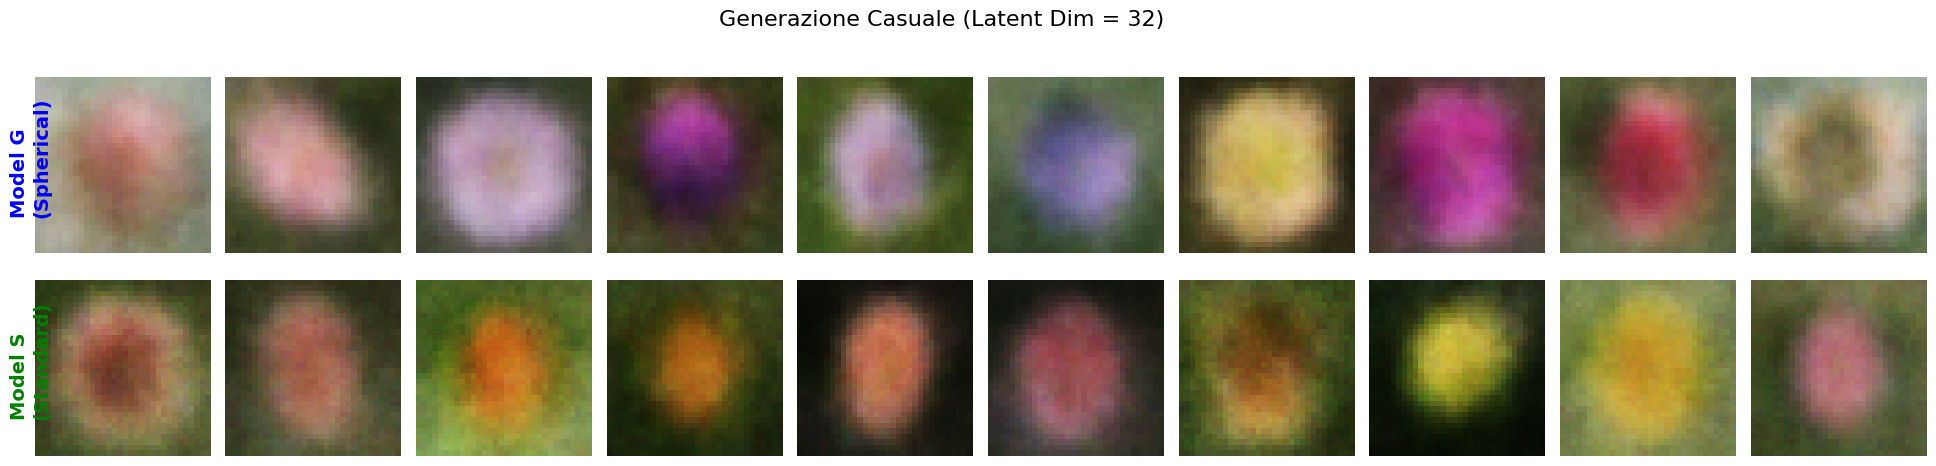

In [65]:
def visualizza_generazione_casuale(model_s, model_v, device, latent_dim, n_images=10):
    """
    Genera immagini da rumore casuale (Latent Space Sampling).
    - Model G: samples uniformly on the sphere.
    - Model S: samples from a standard Gaussian distribution.
    """
    print(f"Generazione di {n_images} nuove immagini da rumore casuale (Dim={latent_dim})...")

    model_s.eval()
    model_v.eval()

    # 1. Generazione Vettori Latenti (Z)

    # A. Per il Sferico: Gaussiana -> Normalizzazione L2
    # Questo garantisce una distribuzione UNIFORME sulla superficie della sfera
    z_s_raw = torch.randn(n_images, latent_dim).to(device)
    z_s = F.normalize(z_s_raw, p=2, dim=1)

    # B. Per il VAE Standard: Gaussiana Pura (N(0,1))
    z_v = torch.randn(n_images, latent_dim).to(device)

    # 2. Decoding (Generazione Immagini)
    with torch.no_grad():
        # Usiamo direttamente il metodo .decode() definito nelle classi
        gen_s = model_s.decode(z_s).cpu()
        gen_v = model_v.decode(z_v).cpu()

    # 3. Plotting
    fig, axes = plt.subplots(2, n_images, figsize=(20, 5))

    for i in range(n_images):
        # --- Riga 1: Generazione Sferica ---
        #axes[0, i].imshow(gen_s[i].reshape(32, 32), cmap='gray')
        axes[0, i].imshow(gen_s[i].view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1]).permute(1, 2, 0))
        axes[0, i].axis('off')

        # --- Riga 2: Generazione Gaussiana ---
        #axes[1, i].imshow(gen_v[i].reshape(32, 32), cmap='gray')
        axes[1, i].imshow(gen_v[i].view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1]).permute(1, 2, 0))
        axes[1, i].axis('off')

    # Titoli descrittivi
    axes[0, 0].text(-5, 14, "Model G\n(Spherical)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='blue')
    axes[1, 0].text(-5, 14, "Model S\n(Standard)", fontsize=14, rotation=90, verticalalignment='center', fontweight='bold', color='green')

    plt.suptitle(f"Generazione Casuale (Latent Dim = {latent_dim})", fontsize=16)
    plt.tight_layout(rect=[0.03, 0, 1, 1])
    plt.show()

# Esempio di utilizzo:
# Assicurati di passare la variabile LATENT_DIM corretta

visualizza_generazione_casuale(model_s, model_v, DEVICE, LATENT_DIM)

##📊PCA

Estrazione vettori latenti dal Training Set...
Calcolo PCA su 5000 punti...


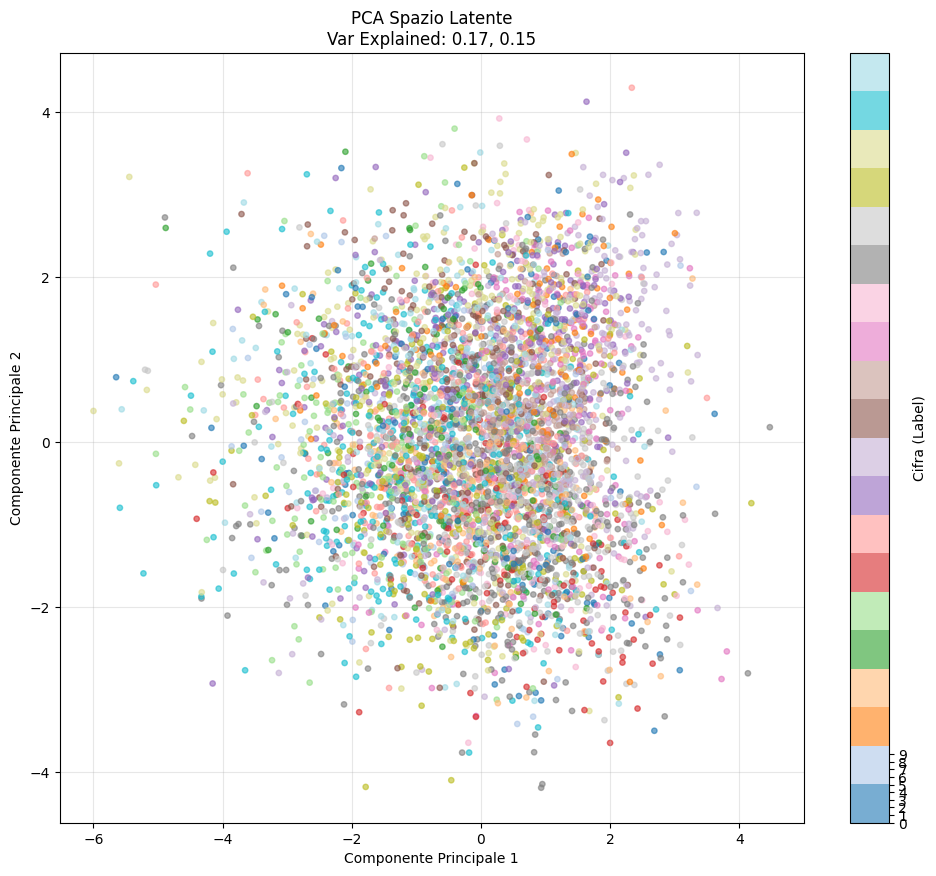

In [66]:
def visualizza_pca_training(model, device, num_points=5000):
    print("Estrazione vettori latenti dal Training Set...")
    model.eval()

    loader = test_loader

    all_z = []
    all_labels = []

    # Raccogliamo i dati
    count = 0
    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device).view(-1, INPUT_DIM)

            # --- MODIFICA ROBUSTA ---
            # model.encode può restituire (mu, scale) oppure (mu, logvar)
            # Usando *rest prendiamo sempre il primo elemento (mu) e ignoriamo il resto
            mu, *rest = model.encode(data)

            all_z.append(mu.cpu().numpy())
            all_labels.append(labels.numpy())

            count += len(labels)
            if count >= num_points:
                break

    # Convertiamo in array numpy unici
    X = np.concatenate(all_z)[:num_points]
    y = np.concatenate(all_labels)[:num_points]

    print(f"Calcolo PCA su {X.shape[0]} punti...")

    # Appliciamo PCA per ridurre a 2 dimensioni
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    # --- Plotting ---
    plt.figure(figsize=(12, 10))

    # Scatter plot con colori diversi per ogni cifra (0-9)
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab20', alpha=0.6, s=15)

    # Legenda e abbellimenti
    plt.colorbar(scatter, ticks=range(10), label='Cifra (Label)')

    # Titolo dinamico
    # Se la varianza spiegata è alta, la PCA è una buona rappresentazione
    var_ratio = pca.explained_variance_ratio_
    plt.title(f'PCA Spazio Latente\nVar Explained: {var_ratio[0]:.2f}, {var_ratio[1]:.2f}')

    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.grid(True, alpha=0.3)

    plt.show()


visualizza_pca_training(model_v, DEVICE)

##📊Interpolazione

Confronto Interpolazione: Slerp (Sferico) vs Lerp (VAE)...


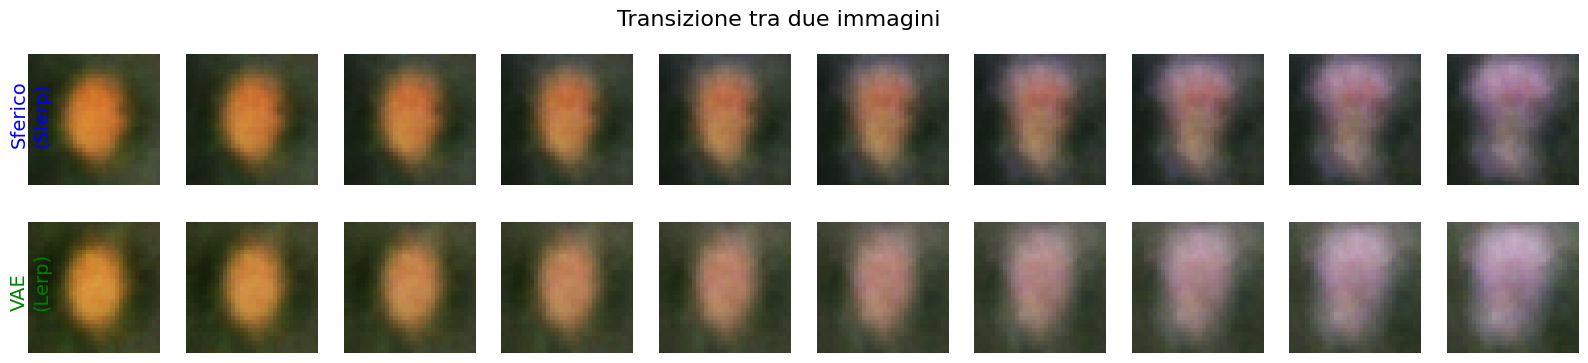

In [67]:
import numpy as np

def slerp(val, low, high):
    """Spherical Linear Interpolation"""
    omega = torch.acos(torch.clamp(torch.sum(low/torch.norm(low) * high/torch.norm(high)), -1, 1))
    so = torch.sin(omega)
    if so == 0:
        return (1.0-val) * low + val * high # Fallback lineare se sono paralleli
    return torch.sin((1.0-val)*omega) / so * low + torch.sin(val*omega) / so * high

def lerp(val, low, high):
    """Linear Interpolation (Standard)"""
    return (1.0 - val) * low + val * high

def visualizza_interpolazione(model_s, model_v, device, steps=10):
    print("Confronto Interpolazione: Slerp (Sferico) vs Lerp (VAE)...")

    # Prendiamo due immagini dal test set: Start e End
    loader = test_loader
    images, _ = next(iter(loader))
    img1, img2 = images[0].to(device), images[1].to(device)

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # Encoding
        # Nota: model_s restituisce (recon, z, ...). Prendiamo z [index 1]
        z1_s = model_s.encode(img1.view(-1, INPUT_DIM))[0] # Prende mu
        z2_s = model_s.encode(img2.view(-1, INPUT_DIM))[0]

        z1_v = model_v.encode(img1.view(-1, INPUT_DIM))[0] # Prende mu
        z2_v = model_v.encode(img2.view(-1, INPUT_DIM))[0]

        # Generazione step intermedi
        ratios = np.linspace(0, 1, steps)

        pics_s = []
        pics_v = []

        for r in ratios:
            # Sferico -> SLERP
            z_interp_s = slerp(r, z1_s, z2_s)
            pics_s.append(model_s.decode(z_interp_s).cpu().view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1]).permute(1, 2, 0))

            # VAE -> LERP
            z_interp_v = lerp(r, z1_v, z2_v)
            pics_v.append(model_v.decode(z_interp_v).cpu().view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1]).permute(1, 2, 0))

    # Plotting
    fig, axes = plt.subplots(2, steps, figsize=(20, 4))

    for i in range(steps):
        axes[0, i].imshow(pics_s[i], cmap='gray')
        axes[0, i].axis('off')
        axes[1, i].imshow(pics_v[i], cmap='gray')
        axes[1, i].axis('off')

    axes[0, 0].text(-5, 14, "Sferico\n(Slerp)", fontsize=14, rotation=90, verticalalignment='center', color='blue')
    axes[1, 0].text(-5, 14, "VAE\n(Lerp)", fontsize=14, rotation=90, verticalalignment='center', color='green')

    plt.suptitle("Transizione tra due immagini", fontsize=16)
    plt.show()

# Esegui (dopo aver addestrato su Flowers102 per risultati migliori)
visualizza_interpolazione(model_s, model_v, DEVICE)

##📊Centroidi_gv

Computing latent centroids and average decoded images for Model G and Model S...




In [68]:
def visualizza_centroidi_gv(model_g, model_v, device, latent_dim):
    print("Computing latent centroids and average decoded images for Model G and Model S...")

    # Utilizziamo il test set di Flowers102
    # Un batch size elevato permette di velocizzare il calcolo
    loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

    model_g.eval()
    model_v.eval()

    # --- 1. Inizializzazione degli accumulatori ---
    # Somma dei vettori latenti z per ciascuna classe
    sum_z_g = torch.zeros(NUM_CLASSES, latent_dim).to(device)
    sum_z_v = torch.zeros(NUM_CLASSES, latent_dim).to(device)

    # Conteggio del numero di campioni appartenenti a ogni classe
    class_counts = torch.zeros(NUM_CLASSES).to(device)

    # --- 2. Accumulo dei vettori latenti ---
    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device)

            # Flowers102 restituisce etichette con shape [batch_size, 1]
            # index_add_ richiede invece un vettore monodimensionale [batch_size]
            labels = labels.to(device).squeeze()

            # Encoding of Model G (Spherical VAE):
            # encode restituisce (mu, alpha), quindi prendiamo solo mu
            z_g, *rest = model_g.encode(data.view(-1, INPUT_DIM))

            # Encoding of Model S (Standard VAE):
            # encode restituisce (mu, logvar), quindi prendiamo solo mu
            z_v, *rest = model_v.encode(data.view(-1, INPUT_DIM))

            # Somma dei vettori latenti per classe
            sum_z_g.index_add_(0, labels, z_g)
            sum_z_v.index_add_(0, labels, z_v)

            # Aggiornamento del numero di campioni per classe
            class_counts.index_add_(
                0,
                labels,
                torch.ones_like(labels, dtype=torch.float)
            )

    # --- 3. Calcolo dei centroidi e generazione delle immagini medie ---

    # A. Model S: Euclidean mean in the latent space
    mean_z_v = sum_z_v / class_counts.unsqueeze(1)
    imgs_v = model_v.decode(mean_z_v).cpu()

    # B. Model G: spherical mean obtained by normalizing the sum of latent vectors
    mean_z_g = torch.nn.functional.normalize(sum_z_g, p=2, dim=1)
    imgs_g = model_g.decode(mean_z_g).cpu()

    # --- 4. Visualizzazione dei risultati ---
    fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.5 * NUM_CLASSES, 5))

    for i in range(NUM_CLASSES):
        # Row 1: Model G, spherical version
        axes[0, i].imshow(
            imgs_g[i]
            .view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
            .permute(1, 2, 0)
            .detach()
            .numpy()
        )
        axes[0, i].axis("off")
        axes[0, i].set_title(
            f"{i}\n{CLASS_NAMES[i]}",
            fontsize=11,
            fontweight="bold"
        )

        # Row 2: Model S, standard version
        axes[1, i].imshow(
            imgs_v[i]
            .view(IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
            .permute(1, 2, 0)
            .detach()
            .numpy()
        )
        axes[1, i].axis("off")

    # Etichette descrittive a sinistra
    axes[0, 0].text(
        -0.45, 0.5,
        "Model G\n(Spherical)",
        transform=axes[0, 0].transAxes,
        fontsize=13,
        rotation=90,
        va="center",
        ha="center",
        fontweight="bold"
    )

    axes[1, 0].text(
        -0.45, 0.5,
        "Model S\n(Standard)",
        transform=axes[1, 0].transAxes,
        fontsize=13,
        rotation=90,
        va="center",
        ha="center",
        fontweight="bold"
    )

    plt.suptitle(
        "Average decoded image from class latent centroid - Flowers102",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout(rect=[0.04, 0, 1, 0.95])
    plt.show()


# Esecuzione della funzione
visualizza_centroidi_gv(model_s, model_v, DEVICE, LATENT_DIM)

##📊Tsne_Sferico

Computing t-SNE with cosine metric...


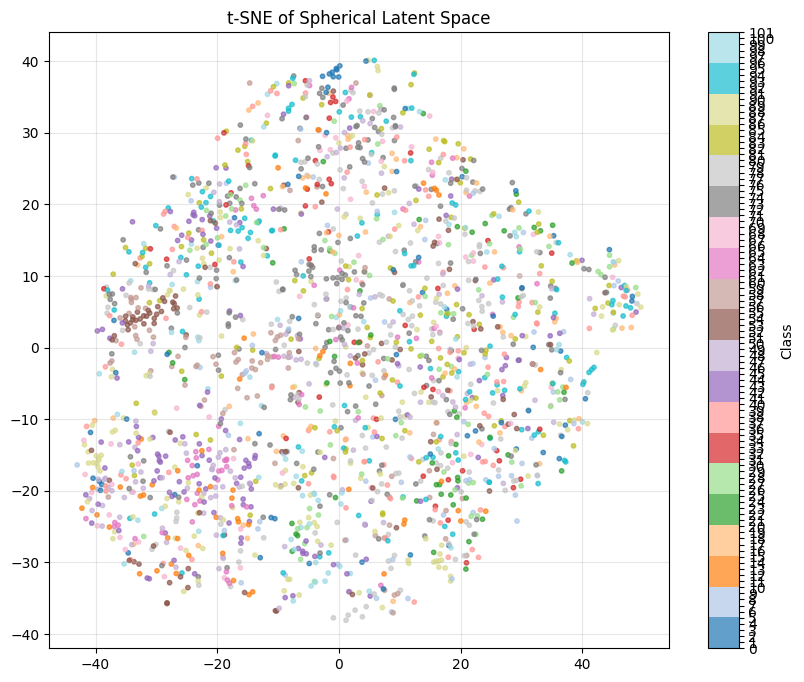

In [69]:
def visualizza_tsne_sferico(model, device, num_points=2000):
    print("Computing t-SNE with cosine metric...")

    model.eval()
    loader = DataLoader(test_dataset, batch_size=128, shuffle=True)

    all_z = []
    all_labels = []
    count = 0

    with torch.no_grad():
        for data, labels in loader:
            data = data.to(device).view(-1, INPUT_DIM)
            z, *rest = model.encode(data)

            all_z.append(z.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

            count += len(labels)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points]
    y = np.concatenate(all_labels, axis=0)[:num_points]

    tsne = TSNE(n_components=2, metric='cosine', init='pca', learning_rate='auto', random_state=42)
    X_embedded = tsne.fit_transform(X)

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y, cmap='tab20', s=10, alpha=0.7)
    plt.colorbar(scatter, ticks=range(NUM_CLASSES), label='Class')
    plt.title("t-SNE of Spherical Latent Space")
    plt.grid(True, alpha=0.3)
    plt.show()

visualizza_tsne_sferico(model_s, DEVICE, 2000)

##📊Confronto Quantitativo Generazione


--- Sharpness comparison on 1000 generated samples ---
Real images - Mean sharpness: 0.0567 (+/- 0.0218)
------------------------------
Spherical - Mean sharpness: 0.0226 (+/- 0.0091)
Standard  - Mean sharpness: 0.0232 (+/- 0.0106)
------------------------------


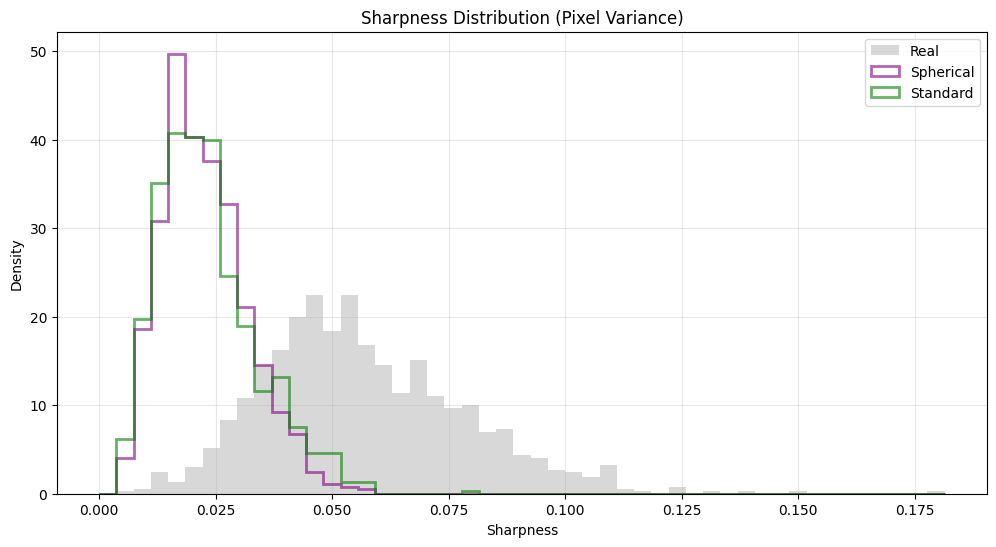

In [70]:
def calcola_statistiche_nitidezza(images_tensor):
    flat_images = images_tensor.view(images_tensor.size(0), -1)
    variances = torch.var(flat_images, dim=1).cpu().numpy()
    return variances

def confronto_quantitativo_generazione(model_g, model_v, device, latent_dim, n_samples=1000):
    print(f"\n--- Sharpness comparison on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    real_imgs, _ = next(iter(real_loader))
    var_real = calcola_statistiche_nitidezza(real_imgs)
    print(f"Real images - Mean sharpness: {var_real.mean():.4f} (+/- {var_real.std():.4f})")

    with torch.no_grad():
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)
        var_g = calcola_statistiche_nitidezza(gen_imgs_g)

        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)
        var_v = calcola_statistiche_nitidezza(gen_imgs_v)

    print("-" * 30)
    print(f"Spherical - Mean sharpness: {var_g.mean():.4f} (+/- {var_g.std():.4f})")
    print(f"Standard  - Mean sharpness: {var_v.mean():.4f} (+/- {var_v.std():.4f})")
    print("-" * 30)

    plt.figure(figsize=(12, 6))
    bins = np.linspace(0, max(var_real.max(), var_g.max(), var_v.max()), 50)

    plt.hist(var_real, bins=bins, alpha=0.3, color='gray', label='Real', density=True)
    plt.hist(var_g, bins=bins, alpha=0.6, color='purple', label='Spherical', density=True, histtype='step', linewidth=2)
    plt.hist(var_v, bins=bins, alpha=0.6, color='green', label='Standard', density=True, histtype='step', linewidth=2)

    plt.title("Sharpness Distribution (Pixel Variance)")
    plt.xlabel("Sharpness")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

confronto_quantitativo_generazione(model_s, model_v, DEVICE, LATENT_DIM, n_samples=1000)

##📊Confronto Diversita


--- Diversity analysis on 1000 generated samples ---
Real dataset diversity: 18.0056
Spherical diversity: 10.5187
Standard diversity:  9.8581
----------------------------------------
Spherical: 58.4% of real diversity
Standard : 54.8% of real diversity
----------------------------------------


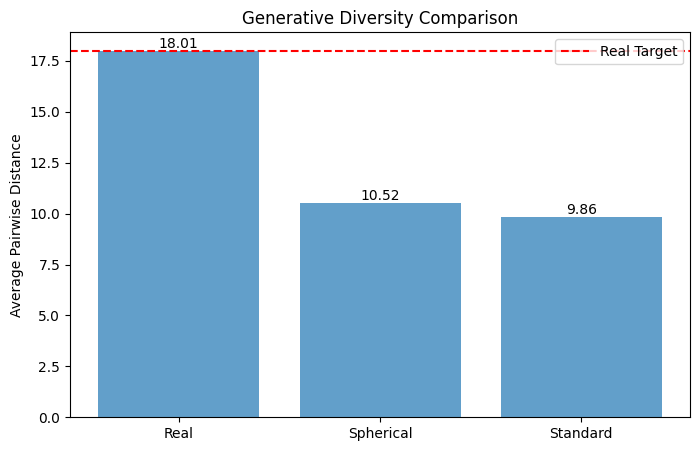

In [71]:
#Diversity statistics
def get_average_pairwise_distance(images_tensor):
    flat = images_tensor.view(images_tensor.size(0), -1)
    dists = torch.cdist(flat, flat, p=2)
    return dists.mean().item()

def confronto_diversita(model_g, model_v, device, latent_dim, n_samples=1000):
    print(f"\n--- Diversity analysis on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    real_imgs, _ = next(iter(real_loader))
    real_imgs = real_imgs.to(device)

    diversity_real = get_average_pairwise_distance(real_imgs)
    print(f"Real dataset diversity: {diversity_real:.4f}")

    with torch.no_grad():
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)
        diversity_g = get_average_pairwise_distance(gen_imgs_g)

        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)
        diversity_v = get_average_pairwise_distance(gen_imgs_v)

    print(f"Spherical diversity: {diversity_g:.4f}")
    print(f"Standard diversity:  {diversity_v:.4f}")

    perc_g = (diversity_g / diversity_real) * 100
    perc_v = (diversity_v / diversity_real) * 100

    print("-" * 40)
    print(f"Spherical: {perc_g:.1f}% of real diversity")
    print(f"Standard : {perc_v:.1f}% of real diversity")
    print("-" * 40)

    plt.figure(figsize=(8, 5))
    methods = ['Real', 'Spherical', 'Standard']
    values = [diversity_real, diversity_g, diversity_v]

    bars = plt.bar(methods, values, alpha=0.7)
    plt.axhline(y=diversity_real, color='red', linestyle='--', label='Real Target')

    plt.ylabel("Average Pairwise Distance")
    plt.title("Generative Diversity Comparison")
    plt.legend()

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.2f}", ha='center', va='bottom')

    plt.show()

confronto_diversita(model_s, model_v, DEVICE, LATENT_DIM)

##📊Inception Like Score

In [72]:

# ============================================================
# 1. Robust CNN Classifier
# ============================================================

class RobustClassifier(nn.Module):
    """
    Simple CNN classifier used to compute an Inception-like Score.

    For Flowers102:
    input shape = [batch, 3, 32, 32]
    output shape = [batch, 102]
    """

    def __init__(self, num_classes):
        super(RobustClassifier, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(IN_CHANNELS, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),   # 32x32 -> 16x16

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),   # 16x16 -> 8x8

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# ============================================================
# 2. Train classifier for Inception-like Score
# ============================================================

def train_or_load_classifier(device, epochs=3):
    """
    Train a simple CNN classifier on the training dataset.
    This classifier is used only for Inception-like Score.
    """

    classifier = RobustClassifier(NUM_CLASSES).to(device)

    print("Training classifier for Inception-like Score...")

    optimizer = optim.Adam(classifier.parameters(), lr=1e-3)

    classifier.train()

    for epoch in range(epochs):
        total_loss = 0.0
        correct = 0
        total = 0

        for data, target in train_loader:
            data = data.to(device)
            target = target.to(device).long()

            optimizer.zero_grad()

            logits = classifier(data)
            loss = F.cross_entropy(logits, target)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * data.size(0)

            pred = torch.argmax(logits, dim=1)
            correct += (pred == target).sum().item()
            total += target.size(0)

        avg_loss = total_loss / total
        acc = correct / total

        print(
            f"Epoch [{epoch + 1}/{epochs}] - "
            f"Loss: {avg_loss:.4f} - "
            f"Accuracy: {acc:.4f}"
        )

    classifier.eval()

    print("Classifier ready.")

    return classifier


# ============================================================
# 3. Generate images from VAE models
# ============================================================

def generate_images_from_model(
    model,
    device,
    latent_dim,
    n_images=1000,
    model_type="standard"
):
    """
    Generate images from a trained VAE model.

    model_type:
    - "standard": sample z from N(0, I)
    - "spherical": sample z from unit sphere
    """

    model.eval()

    with torch.no_grad():
        z = torch.randn(n_images, latent_dim).to(device)

        if model_type == "spherical":
            z = F.normalize(z, p=2, dim=1)

        generated = model.decode(z)

        # If decoder output is flattened, reshape to image format
        if generated.ndim == 2:
            generated = generated.view(
                n_images,
                IN_CHANNELS,
                IMAGE_SIZE[0],
                IMAGE_SIZE[1]
            )

        # Keep values in valid image range
        generated = torch.clamp(generated, 0.0, 1.0)

    return generated.cpu()


# ============================================================
# 4. Calculate Inception-like Score
# ============================================================

def calculate_inception_score(
    generated_images,
    classifier,
    device,
    splits=10,
    batch_size=100
):
    """
    Compute Inception-like Score using the trained classifier.

    Higher score usually means:
    - generated images are easier to classify
    - generated images are more diverse across classes
    """

    classifier.eval()

    preds = []

    gen_dataset = torch.utils.data.TensorDataset(generated_images)
    gen_loader = DataLoader(
        gen_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    with torch.no_grad():
        for batch in gen_loader:
            batch_imgs = batch[0].to(device)

            logits = classifier(batch_imgs)
            pred = F.softmax(logits, dim=1)

            preds.append(pred.cpu().numpy())

    preds = np.concatenate(preds, axis=0)

    scores = []

    n_images = preds.shape[0]
    n_part = n_images // splits

    if n_part == 0:
        raise ValueError(
            "Number of generated images is smaller than number of splits."
        )

    for i in range(splits):
        part = preds[i * n_part : (i + 1) * n_part]

        p_y = np.expand_dims(np.mean(part, axis=0), axis=0)

        kl_div = part * (
            np.log(part + 1e-16) -
            np.log(p_y + 1e-16)
        )

        kl_div = np.sum(kl_div, axis=1)
        avg_kl = np.mean(kl_div)

        scores.append(np.exp(avg_kl))

    return np.mean(scores), np.std(scores)


# ============================================================
# 5. Compare Model S and Model G
# ============================================================

def confronta_inception_score(
    model_s,
    model_g,
    device,
    latent_dim,
    n_images=1000,
    classifier_epochs=3,
    splits=10
):
    """
    Compare Inception-like Score between:

    Model S = Standard VAE
    Model G = Spherical VAE

    In your notebook:
    - model_v is usually Standard VAE
    - model_s is usually Spherical VAE

    Therefore final call should be:
    confronta_inception_score(
        model_s=model_v,
        model_g=model_s,
        ...
    )
    """

    print("================================================")
    print("Inception-like Score Comparison")
    print("Dataset: Flowers102")
    print("Model S = Standard VAE")
    print("Model G = Spherical VAE")
    print("================================================")

    # Train classifier
    classifier = train_or_load_classifier(
        device=device,
        epochs=classifier_epochs
    )

    # Generate images from Model S
    print("\nGenerating images from Model S (Standard VAE)...")

    generated_s = generate_images_from_model(
        model=model_s,
        device=device,
        latent_dim=latent_dim,
        n_images=n_images,
        model_type="standard"
    )

    # Generate images from Model G
    print("Generating images from Model G (Spherical VAE)...")

    generated_g = generate_images_from_model(
        model=model_g,
        device=device,
        latent_dim=latent_dim,
        n_images=n_images,
        model_type="spherical"
    )

    # Calculate score for Model S
    print("\nCalculating Inception-like Score for Model S...")

    score_s_mean, score_s_std = calculate_inception_score(
        generated_images=generated_s,
        classifier=classifier,
        device=device,
        splits=splits
    )

    # Calculate score for Model G
    print("Calculating Inception-like Score for Model G...")

    score_g_mean, score_g_std = calculate_inception_score(
        generated_images=generated_g,
        classifier=classifier,
        device=device,
        splits=splits
    )

    # Create result table
    results = pd.DataFrame({
        "Dataset": [
            "Flowers102",
            "Flowers102"
        ],
        "Model": [
            "Model S (Standard VAE)",
            "Model G (Spherical VAE)"
        ],
        "Inception-like Score Mean": [
            score_s_mean,
            score_g_mean
        ],
        "Inception-like Score Std": [
            score_s_std,
            score_g_std
        ]
    })

    display(results)

    print("\n===== Inception-like Score Results =====")
    print(
        f"Model S (Standard VAE)  : "
        f"{score_s_mean:.4f} ± {score_s_std:.4f}"
    )
    print(
        f"Model G (Spherical VAE) : "
        f"{score_g_mean:.4f} ± {score_g_std:.4f}"
    )

    if score_s_mean > score_g_mean:
        print("\nBetter model according to Inception-like Score: Model S")
    elif score_g_mean > score_s_mean:
        print("\nBetter model according to Inception-like Score: Model G")
    else:
        print("\nBoth models have the same Inception-like Score.")

    return results


# ============================================================
# 6. Run comparison
# ============================================================

is_results = confronta_inception_score(
    model_s=model_v,      # Model S = Standard VAE
    model_g=model_s,      # Model G = Spherical VAE
    device=DEVICE,
    latent_dim=LATENT_DIM,
    n_images=1000,
    classifier_epochs=10,
    splits=10
)

Inception-like Score Comparison
Dataset: Flowers102
Model S = Standard VAE
Model G = Spherical VAE
Training classifier for Inception-like Score...
Epoch [1/10] - Loss: 4.5325 - Accuracy: 0.0240
Epoch [2/10] - Loss: 4.2082 - Accuracy: 0.0948
Epoch [3/10] - Loss: 3.9850 - Accuracy: 0.1323
Epoch [4/10] - Loss: 3.7937 - Accuracy: 0.1594
Epoch [5/10] - Loss: 3.6431 - Accuracy: 0.1771
Epoch [6/10] - Loss: 3.5000 - Accuracy: 0.2073
Epoch [7/10] - Loss: 3.3762 - Accuracy: 0.2292
Epoch [8/10] - Loss: 3.2462 - Accuracy: 0.2344
Epoch [9/10] - Loss: 3.1334 - Accuracy: 0.2604
Epoch [10/10] - Loss: 3.0485 - Accuracy: 0.2990
Classifier ready.

Generating images from Model S (Standard VAE)...
Generating images from Model G (Spherical VAE)...

Calculating Inception-like Score for Model S...
Calculating Inception-like Score for Model G...


,Dataset,Model,Inception-like Score Mean,Inception-like Score Std
0,Flowers102,Model S (Standard VAE),1.609771,0.053745
1,Flowers102,Model G (Spherical VAE),1.531281,0.038726



===== Inception-like Score Results =====
Model S (Standard VAE)  : 1.6098 ± 0.0537
Model G (Spherical VAE) : 1.5313 ± 0.0387

Better model according to Inception-like Score: Model S


FID comparison on Flowers102
Model S   = Standard VAE
Model G   = Spherical / Geodesic VAE
Model vMF = vMF-inspired VAE
Generating 2000 images from Model S...
Generating 2000 images from Model G...
Generating 2000 images from Model vMF...
------------------------------------------------------------
Computing FID with Inception features dims=64...


/tmp/ipykernel_57/2065029746.py:212: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(sigma1 @ sigma2)


FID-64 Model S   (Standard VAE)       : 0.7537
FID-64 Model G   (Spherical VAE)      : 0.8739
FID-64 Model vMF (vMF VAE)            : 0.7877
Best model for FID-64: Model S
------------------------------------------------------------
Computing FID with Inception features dims=192...
FID-192 Model S   (Standard VAE)       : 9.4370
FID-192 Model G   (Spherical VAE)      : 11.6619
FID-192 Model vMF (vMF VAE)            : 10.3412
Best model for FID-192: Model S
------------------------------------------------------------
Computing FID with Inception features dims=768...
FID-768 Model S   (Standard VAE)       : 2.0228
FID-768 Model G   (Spherical VAE)      : 1.9544
FID-768 Model vMF (vMF VAE)            : 1.9043
Best model for FID-768: Model vMF
------------------------------------------------------------
Computing FID with Inception features dims=2048...
FID-2048 Model S   (Standard VAE)       : 256.9416
FID-2048 Model G   (Spherical VAE)      : 244.5032
FID-2048 Model vMF (vMF VAE)        

,Dataset,FID dimension,Model S (Standard VAE),Model G (Spherical VAE),Model vMF (vMF VAE),Best model
0,Flowers102,64,0.753674,0.873876,0.787689,Model S
1,Flowers102,192,9.437017,11.661872,10.341209,Model S
2,Flowers102,768,2.022759,1.954390,1.904338,Model vMF
3,Flowers102,2048,256.941554,244.503155,235.656808,Model vMF


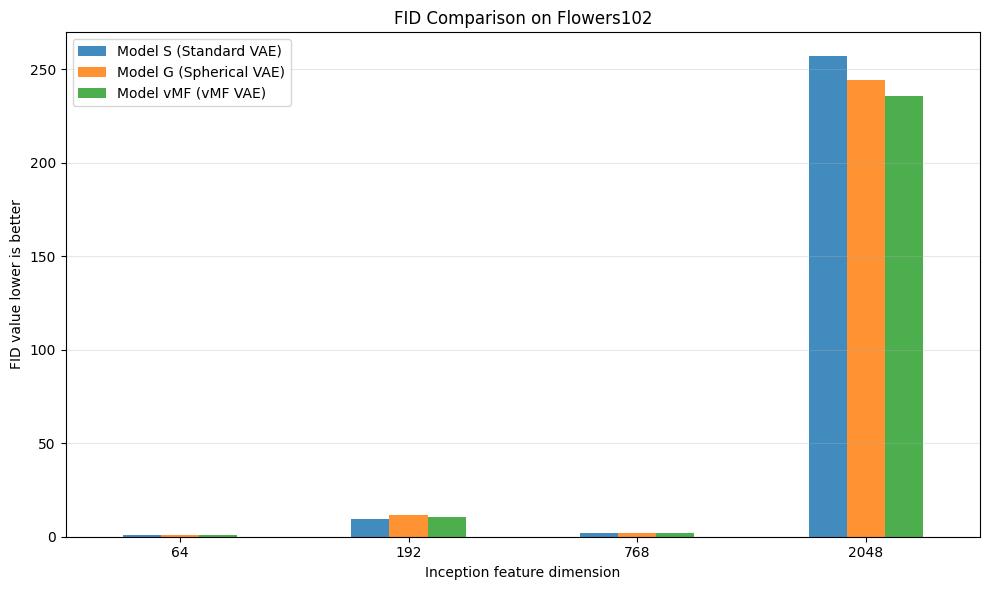

In [73]:
# ============================================================
# FID module for Flowers102: three-model comparison
# Model S   = Standard VAE
# Model G   = Spherical / Geodesic VAE
# Model vMF = vMF-inspired VAE
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from scipy.linalg import sqrtm

try:
    from torchvision.models import inception_v3, Inception_V3_Weights
    _INCEPTION_WEIGHTS = Inception_V3_Weights.DEFAULT
except Exception:
    from torchvision.models import inception_v3
    _INCEPTION_WEIGHTS = None


FID_DIMS_LIST = [64, 192, 768, 2048]
FID_N_SAMPLES = 2000
FID_BATCH_SIZE = 64
DATASET_NAME_FOR_FID = "Flowers102"


class InceptionFeatureExtractor(nn.Module):
    """
    Extract InceptionV3 features.

    Supported output dimensions:
    - 64
    - 192
    - 768
    - 2048
    """

    BLOCK_INDEX_BY_DIM = {
        64: 0,
        192: 1,
        768: 2,
        2048: 3
    }

    def __init__(self, device, dims=2048):
        super().__init__()

        if dims not in self.BLOCK_INDEX_BY_DIM:
            raise ValueError(
                f"dims={dims} is not supported. "
                f"Use one of {list(self.BLOCK_INDEX_BY_DIM.keys())}"
            )

        self.dims = dims
        self.output_block = self.BLOCK_INDEX_BY_DIM[dims]

        if _INCEPTION_WEIGHTS is not None:
            self.model = inception_v3(weights=_INCEPTION_WEIGHTS, transform_input=False)
        else:
            self.model = inception_v3(pretrained=True, transform_input=False)

        self.model.eval()
        self.model.to(device)

    def forward(self, x):
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        x = F.interpolate(
            x,
            size=(299, 299),
            mode="bilinear",
            align_corners=False
        )

        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        x = (x - mean) / std

        # Block 0 -> 64 dims
        x = self.model.Conv2d_1a_3x3(x)
        x = self.model.Conv2d_2a_3x3(x)
        x = self.model.Conv2d_2b_3x3(x)
        x = F.max_pool2d(x, kernel_size=3, stride=2)

        if self.output_block == 0:
            x = F.adaptive_avg_pool2d(x, output_size=(1, 1))
            return torch.flatten(x, 1)

        # Block 1 -> 192 dims
        x = self.model.Conv2d_3b_1x1(x)
        x = self.model.Conv2d_4a_3x3(x)
        x = F.max_pool2d(x, kernel_size=3, stride=2)

        if self.output_block == 1:
            x = F.adaptive_avg_pool2d(x, output_size=(1, 1))
            return torch.flatten(x, 1)

        # Block 2 -> 768 dims
        x = self.model.Mixed_5b(x)
        x = self.model.Mixed_5c(x)
        x = self.model.Mixed_5d(x)
        x = self.model.Mixed_6a(x)
        x = self.model.Mixed_6b(x)
        x = self.model.Mixed_6c(x)
        x = self.model.Mixed_6d(x)
        x = self.model.Mixed_6e(x)

        if self.output_block == 2:
            x = F.adaptive_avg_pool2d(x, output_size=(1, 1))
            return torch.flatten(x, 1)

        # Block 3 -> 2048 dims
        x = self.model.Mixed_7a(x)
        x = self.model.Mixed_7b(x)
        x = self.model.Mixed_7c(x)
        x = self.model.avgpool(x)
        return torch.flatten(x, 1)


def get_real_images_from_loader(loader, n_samples, device):
    imgs = []
    collected = 0

    for batch in loader:
        if isinstance(batch, (list, tuple)):
            data = batch[0]
        else:
            data = batch

        imgs.append(data)
        collected += data.size(0)

        if collected >= n_samples:
            break

    imgs = torch.cat(imgs, dim=0)[:n_samples].to(device)

    if imgs.ndim == 3:
        imgs = imgs.unsqueeze(1)

    return imgs.clamp(0, 1)


def sample_latent_for_model(sample_mode, n_samples, latent_dim, device):
    if sample_mode in ["spherical", "vmf"]:
        z = torch.randn(n_samples, latent_dim, device=device)
        z = F.normalize(z, p=2, dim=1)
    elif sample_mode == "standard":
        z = torch.randn(n_samples, latent_dim, device=device)
    else:
        raise ValueError(f"Unknown sample_mode: {sample_mode}")

    return z


def get_generated_images(model, latent_dim, n_samples, device, sample_mode):
    model.eval()

    with torch.no_grad():
        z = sample_latent_for_model(
            sample_mode=sample_mode,
            n_samples=n_samples,
            latent_dim=latent_dim,
            device=device
        )

        imgs = model.decode(z)

        if imgs.ndim == 2:
            imgs = imgs.view(
                -1,
                IN_CHANNELS,
                IMAGE_SIZE[0],
                IMAGE_SIZE[1]
            )

        if imgs.ndim == 3:
            imgs = imgs.unsqueeze(1)

        imgs = imgs.clamp(0, 1)

    return imgs


def get_activations(images, feature_extractor, batch_size=64):
    acts = []
    feature_extractor.eval()

    with torch.no_grad():
        for i in range(0, images.size(0), batch_size):
            batch = images[i:i + batch_size]
            feat = feature_extractor(batch)
            acts.append(feat.detach().cpu().numpy())

    acts = np.concatenate(acts, axis=0).astype(np.float64)
    return acts


def compute_statistics(activations):
    mu = np.mean(activations, axis=0)
    sigma = np.cov(activations, rowvar=False)
    return mu, sigma


def calculate_fid(mu1, sigma1, mu2, sigma2, eps=1e-6):
    diff = mu1 - mu2
    covmean = sqrtm(sigma1 @ sigma2)

    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset) @ (sigma2 + offset))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return float(fid)


def compute_fid_from_generated_images(real_imgs, fake_imgs, feature_extractor):
    real_acts = get_activations(real_imgs, feature_extractor, batch_size=FID_BATCH_SIZE)
    fake_acts = get_activations(fake_imgs, feature_extractor, batch_size=FID_BATCH_SIZE)

    mu_real, sigma_real = compute_statistics(real_acts)
    mu_fake, sigma_fake = compute_statistics(fake_acts)

    return calculate_fid(mu_real, sigma_real, mu_fake, sigma_fake)


def confronta_fid_tre_modelli(
    model_s,
    model_g,
    model_vmf,
    real_loader,
    latent_dim,
    device,
    n_samples=2000,
    dims_list=None
):
    """
    Compare FID among three models.

    Model S   = Standard VAE
    Model G   = Spherical / Geodesic VAE
    Model vMF = vMF-inspired VAE
    """

    if dims_list is None:
        dims_list = FID_DIMS_LIST

    print("============================================================")
    print(f"FID comparison on {DATASET_NAME_FOR_FID}")
    print("Model S   = Standard VAE")
    print("Model G   = Spherical / Geodesic VAE")
    print("Model vMF = vMF-inspired VAE")
    print("============================================================")

    print(f"Collecting {n_samples} real images...")
    real_imgs = get_real_images_from_loader(real_loader, n_samples, device)

    print(f"Generating {n_samples} images from Model S...")
    fake_s = get_generated_images(
        model=model_s,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        sample_mode="standard"
    )

    print(f"Generating {n_samples} images from Model G...")
    fake_g = get_generated_images(
        model=model_g,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        sample_mode="spherical"
    )

    print(f"Generating {n_samples} images from Model vMF...")
    fake_vmf = get_generated_images(
        model=model_vmf,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        sample_mode="vmf"
    )

    rows = []

    for dims in dims_list:
        print("-" * 60)
        print(f"Computing FID with Inception features dims={dims}...")

        feature_extractor = InceptionFeatureExtractor(device=device, dims=dims)

        fid_s = compute_fid_from_generated_images(real_imgs, fake_s, feature_extractor)
        fid_g = compute_fid_from_generated_images(real_imgs, fake_g, feature_extractor)
        fid_vmf = compute_fid_from_generated_images(real_imgs, fake_vmf, feature_extractor)

        fid_values = {
            "Model S": fid_s,
            "Model G": fid_g,
            "Model vMF": fid_vmf
        }

        best_model = min(fid_values, key=fid_values.get)

        print(f"FID-{dims} Model S   (Standard VAE)       : {fid_s:.4f}")
        print(f"FID-{dims} Model G   (Spherical VAE)      : {fid_g:.4f}")
        print(f"FID-{dims} Model vMF (vMF VAE)            : {fid_vmf:.4f}")
        print(f"Best model for FID-{dims}: {best_model}")

        rows.append({
            "Dataset": DATASET_NAME_FOR_FID,
            "FID dimension": dims,
            "Model S (Standard VAE)": fid_s,
            "Model G (Spherical VAE)": fid_g,
            "Model vMF (vMF VAE)": fid_vmf,
            "Best model": best_model
        })

    results = pd.DataFrame(rows)
    display(results)

    # Bar chart for all dimensions
    plot_df = results.set_index("FID dimension")[[
        "Model S (Standard VAE)",
        "Model G (Spherical VAE)",
        "Model vMF (vMF VAE)"
    ]]

    ax = plot_df.plot(kind="bar", figsize=(10, 6), alpha=0.85)
    ax.set_title(f"FID Comparison on {DATASET_NAME_FOR_FID}")
    ax.set_ylabel("FID value lower is better")
    ax.set_xlabel("Inception feature dimension")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return results


# ============================================================
# Run FID comparison
# ============================================================

REAL_LOADER_FOR_FID = globals().get(
    "test_loader",
    globals().get("data_loader", globals().get("train_loader"))
)

if REAL_LOADER_FOR_FID is None:
    raise NameError("No valid loader found. Expected test_loader, data_loader, or train_loader.")

fid_results_three_models = confronta_fid_tre_modelli(
    model_s=model_v,       # Model S = Standard VAE
    model_g=model_s,       # Model G = Spherical / Geodesic VAE
    model_vmf=model_vmf,   # Model vMF = vMF-inspired VAE
    real_loader=REAL_LOADER_FOR_FID,
    latent_dim=LATENT_DIM,
    device=DEVICE,
    n_samples=FID_N_SAMPLES,
    dims_list=FID_DIMS_LIST
)
